# Análise e comparação — TF-IDF + Regressão Logística × BERTimbau

Este notebook compara as previsões dos modelos no mesmo teste do HateBR. Os resultados quantitativos são calculados dos CSVs. Não há novo treinamento.

**Análise qualitativa:** foram lidos 40 erros de cada modelo para elaborar categorias exploratórias. As categorias foram propostas com auxílio de IA e precisam de revisão das integrantes; não constituem anotação humana independente. Os rótulos originais do dataset são preservados, inclusive quando a leitura do comentário sugere ambiguidade. Uma categoria não demonstra por que o modelo errou.

Execute no Colab, com CPU suficiente. Os CSVs públicos são carregados do repositório. Se os arquivos forem atualizados, as saídas devem ser recalculadas. Não use esta análise do teste para selecionar hiperparâmetros e depois apresentar o mesmo teste como avaliação independente.

## 1. Importações
Importa bibliotecas já usadas no projeto, sem carregar os modelos nem exigir GPU.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score
PASTA = Path('results_analise')
PASTA.mkdir(exist_ok=True)


## 2. Carregamento e conferência
Verifica esquema, IDs únicos, rótulos, tamanho e correspondência exata dos comentários. O cruzamento é feito pelo ID, sem presumir a mesma ordem dos arquivos.

In [2]:
BASE = 'https://raw.githubusercontent.com/CamiMenezes/indentificador-ofensivo/main/results/'
baseline = pd.read_csv(BASE + 'previsoes_baseline.csv')
bertimbau = pd.read_csv(BASE + 'previsoes_bertimbau.csv')
for tabela, pred in [(baseline, 'pred_baseline'), (bertimbau, 'pred_bertimbau')]:
    assert {'id', 'comentario', 'label', pred}.issubset(tabela.columns)
    assert len(tabela) == 1400 and tabela['id'].is_unique
    assert not tabela[['id', 'comentario', 'label', pred]].isna().any().any()
    assert set(tabela['label']) == {0, 1}
    assert set(tabela[pred]).issubset({0, 1})
assert set(baseline['id']) == set(bertimbau['id'])
dados = baseline.merge(bertimbau, on='id', suffixes=('_base', '_bert'), validate='one_to_one')
assert dados['comentario_base'].equals(dados['comentario_bert'])
assert dados['label_base'].equals(dados['label_bert'])
dados = dados.rename(columns={'comentario_base': 'comentario', 'label_base': 'label'})
dados = dados[['id', 'comentario', 'label', 'pred_baseline', 'pred_bertimbau']]
assert dados['label'].value_counts().to_dict() == {0: 700, 1: 700}
print('Conferência aprovada: mesmos 1.400 IDs, comentários e rótulos; 700 de cada classe.')


Conferência aprovada: mesmos 1.400 IDs, comentários e rótulos; 700 de cada classe.


## 3. Métricas
Calcula métricas com precisão completa; o arredondamento é apenas visual. F1 macro é a média dos F1 das classes, e não a média harmônica entre precisão macro e revocação macro.

In [3]:
relatorios, resumo, classes = {}, [], []
for nome, coluna in [('Baseline', 'pred_baseline'), ('BERTimbau', 'pred_bertimbau')]:
    rel = classification_report(dados['label'], dados[coluna], labels=[0, 1],
        target_names=['Não ofensivo', 'Ofensivo'], output_dict=True, zero_division=0)
    relatorios[nome] = rel
    resumo.append({'Modelo': nome, 'Acurácia': accuracy_score(dados['label'], dados[coluna]),
        'Precisão macro': rel['macro avg']['precision'], 'Revocação macro': rel['macro avg']['recall'],
        'F1 macro': rel['macro avg']['f1-score'], 'Erros': int((dados['label'] != dados[coluna]).sum())})
    for classe in ['Não ofensivo', 'Ofensivo']:
        classes.append({'Modelo': nome, 'Classe': classe, **rel[classe]})
resumo = pd.DataFrame(resumo).set_index('Modelo')
por_classe = pd.DataFrame(classes)
display(resumo.round(4))
display(por_classe.round(4))
ganho_f1_pp = 100 * (resumo.loc['BERTimbau', 'F1 macro'] - resumo.loc['Baseline', 'F1 macro'])
print(f'Ganho de F1 macro: {ganho_f1_pp:.2f} pontos percentuais.')


,Acurácia,Precisão macro,Revocação macro,F1 macro,Erros
Modelo,,,,,
Baseline,0.8279,0.8281,0.8279,0.8278,241
BERTimbau,0.9179,0.9184,0.9179,0.9178,115


,Modelo,Classe,precision,recall,f1-score,support
0,Baseline,Não ofensivo,0.8370,0.8143,0.8255,700.0
1,Baseline,Ofensivo,0.8192,0.8414,0.8302,700.0
2,BERTimbau,Não ofensivo,0.9034,0.9357,0.9193,700.0
3,BERTimbau,Ofensivo,0.9333,0.9000,0.9164,700.0


Ganho de F1 macro: 9.00 pontos percentuais.


## 4. Matrizes de confusão e F1
Linhas indicam classe real e colunas, previsão. Os dois gráficos de matriz usam a mesma escala de cores.

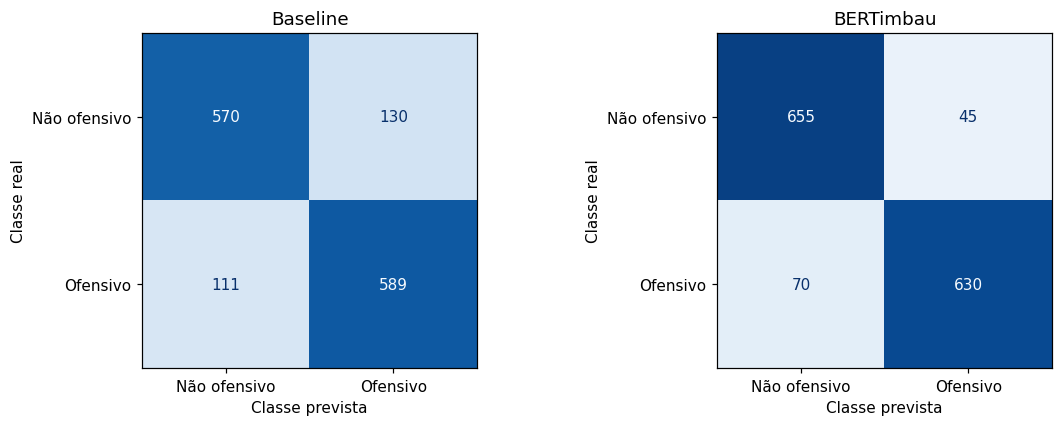

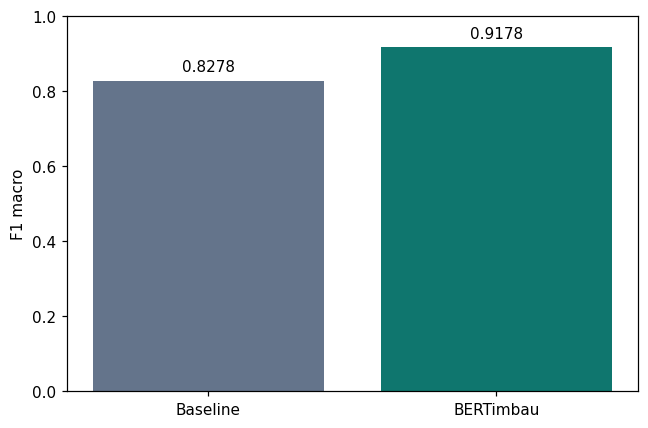

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, coluna) in zip(axes, [('Baseline', 'pred_baseline'), ('BERTimbau', 'pred_bertimbau')]):
    matriz = confusion_matrix(dados['label'], dados[coluna], labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=['Não ofensivo', 'Ofensivo']).plot(
        ax=ax, cmap='Blues', colorbar=False, im_kw={'vmin': 0, 'vmax': 700})
    ax.set_title(nome)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')
fig.tight_layout()
fig.savefig(PASTA / 'matrizes_comparacao.png', dpi=180)
plt.show()
fig, ax = plt.subplots(figsize=(6, 4))
valores = resumo['F1 macro']
barras = ax.bar(valores.index, valores.values, color=['#64748b', '#0f766e'])
ax.set_ylim(0, 1)
ax.set_ylabel('F1 macro')
ax.bar_label(barras, labels=[f'{v:.4f}' for v in valores], padding=4)
fig.tight_layout()
fig.savefig(PASTA / 'f1_macro_comparacao.png', dpi=180)
plt.show()


## 5. Sobreposição dos erros
Separa os erros compartilhados e os casos em que apenas um modelo errou. Essas diferenças são observações da amostra de teste, não explicações causais.

In [5]:
dados['erro_baseline'] = dados['label'] != dados['pred_baseline']
dados['erro_bertimbau'] = dados['label'] != dados['pred_bertimbau']
condicoes = [~dados.erro_baseline & ~dados.erro_bertimbau,
             dados.erro_baseline & ~dados.erro_bertimbau,
             ~dados.erro_baseline & dados.erro_bertimbau,
             dados.erro_baseline & dados.erro_bertimbau]
nomes = ['Ambos acertaram', 'Só baseline errou', 'Só BERTimbau errou', 'Ambos erraram']
dados['situacao'] = np.select(condicoes, nomes, default='Verificar')
sobreposicao = dados['situacao'].value_counts().reindex(nomes, fill_value=0)
display(sobreposicao.rename('Quantidade').to_frame())
for nome, coluna in [('baseline', 'erro_baseline'), ('bertimbau', 'erro_bertimbau')]:
    dados.loc[dados[coluna]].to_csv(PASTA / f'erros_{nome}.csv', index=False)
dados.to_csv(PASTA / 'comparacao_por_comentario.csv', index=False)


,Quantidade
situacao,
Ambos acertaram,1101
Só baseline errou,184
Só BERTimbau errou,58
Ambos erraram,57


## 6. Tempo de execução
Lê o registro do BERTimbau. O tempo do baseline é o valor arredondado exibido no notebook. Os intervalos e hardwares não foram controlados: não calcule uma razão de velocidade como benchmark equivalente.

In [6]:
registro = pd.read_json(BASE + 'execucao_bertimbau.json', typ='series').to_dict()
tempos = pd.DataFrame([
    {'Modelo': 'Baseline', 'Tempo registrado (s)': 1.3, 'Hardware': 'Não registrado',
     'Escopo': 'Vetorização do treino + transformação do teste + ajuste'},
    {'Modelo': 'BERTimbau', 'Tempo registrado (s)': registro['tempo_treino_segundos'],
     'Hardware': registro['gpu'], 'Escopo': 'Somente treinamento; sem download, tokenização ou avaliação'}])
display(tempos)
print('Tokenização do treino BERTimbau (s):', registro['tempo_tokenizacao_treino_segundos'])


,Modelo,Tempo registrado (s),Hardware,Escopo
0,Baseline,1.300000,Não registrado,Vetorização do treino + transformação do teste + ajuste
1,BERTimbau,364.235969,Tesla T4,"Somente treinamento; sem download, tokenização ou avaliação"


Tokenização do treino BERTimbau (s): 0.5995246559999711


## 7. Leitura qualitativa de 40 erros por modelo
A amostragem usa `sample(40, random_state=42)` separadamente nos erros de cada modelo. As amostras podem compartilhar comentários. Cada item recebe uma categoria principal exploratória, o que simplifica fenômenos que podem coexistir.

As propostas abaixo derivam da leitura textual assistida por IA. O grupo deve revisar os 80 registros e, quando necessário, alterar categoria e justificativa no CSV exportado. A coluna de status preserva essa pendência. A classificação não mede toda a população de erros e não permite atribuir mecanismos internos ao modelo. Termos ofensivos do corpus são mantidos para permitir auditoria.

In [7]:
anotacoes = pd.DataFrame([{'modelo': 'baseline', 'id': 3996, 'comentario': 'Uma verdadeira absoluta 👏👏👏👏', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 4538, 'comentario': 'mulher não é uma pessoa, por isso está acima da sociedade', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'O enunciado permite leituras distintas de gênero e valorização; o contexto não está disponível.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3199, 'comentario': 'Estou indignada com tanta violência e preconceito. Estamos com a senhora, Ministra.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'O texto manifesta apoio e repúdio à violência; o rótulo ofensivo exige cautela interpretativa.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 6058, 'comentario': 'Projeto do George Soros, patrocinador da esquerda no mundo.', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 4376, 'comentario': 'Mds! Até quando vão permitir isso com as mulheres desse país?!!!', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 2451, 'comentario': 'Que seja condenado', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 4080, 'comentario': 'Que consciência tem essa garota!', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 6634, 'comentario': 'Só amigos que se cumprimentam assim 👏👏👏👏', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 6201, 'comentario': '@fernandohaddadoficial Então, queremos saber se já foi feita a correção da tabela do IRPF pra esse ano? Pq ano passado foi feita uma pequena correção e quem ganha até 2.640,00 (dois salários mínimos) ficou isento de pagar o IR e esse ano quem ganha 2.824,00 reais (dois salários mínimos) está isento de pagar o IR ou não foi feita a correção da tabela do IRPF????', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 1605, 'comentario': 'Esse facista , racista e homofóbico ainda está vivo na política??? Vc não não me representa !!!', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa explícita não reconhecida', 'justificativa': 'Leitura exploratória do texto: ofensa explícita não reconhecida. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 2871, 'comentario': 'Continuará sendo a diva das Américas e a única mulher eleita e reeleita presidente da república federativa do Brasil! Engulam isso, canalhas fascistas.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa explícita não reconhecida', 'justificativa': 'Leitura exploratória do texto: ofensa explícita não reconhecida. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 2100, 'comentario': 'Ñ suporto essas palhaçadas esse ñ. me representa.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa explícita não reconhecida', 'justificativa': 'Leitura exploratória do texto: ofensa explícita não reconhecida. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 2156, 'comentario': 'Maldito seja para todo o sempre.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa explícita não reconhecida', 'justificativa': 'Leitura exploratória do texto: ofensa explícita não reconhecida. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 5406, 'comentario': 'E os trabalhadores nem aí, não existe vontade de lutar por direitos, greve geral só na história', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política confundida com ofensa', 'justificativa': 'Leitura exploratória do texto: crítica política confundida com ofensa. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3504, 'comentario': 'A gente não precisa da sua pena, tenha pena do seu país que não tem florestas!!!', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política confundida com ofensa', 'justificativa': 'Leitura exploratória do texto: crítica política confundida com ofensa. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 5794, 'comentario': 'Deputados, senadores quebram decoro, rasgam a constituição e nada acontece com vcs!', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política confundida com ofensa', 'justificativa': 'Leitura exploratória do texto: crítica política confundida com ofensa. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 5431, 'comentario': 'QUANDO VAI ASSINAR UMA LEI PARA ACABAR COM OS CARTOES CORPORATIVOS? O PRESIDENTE NAO VE QUE CADA CARTAO É UMA TORNEIRA ABERTA PARA O GASTO DO DINHEIRO PUBLICO? PARA DIZER QUE FAZ ALGUMA COISA, CRIA UM IMPOSTO, SOBRE QUEM TRABALHA, NAO TIRA NADA DA CLASSE POLITICA!', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política confundida com ofensa', 'justificativa': 'Leitura exploratória do texto: crítica política confundida com ofensa. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3895, 'comentario': 'E ele quer decidir até as eleições vizinhas.', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política confundida com ofensa', 'justificativa': 'Leitura exploratória do texto: crítica política confundida com ofensa. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 6843, 'comentario': 'Dengue precisa e de vacina né de vídeo bonito não cadê as vacina', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política confundida com ofensa', 'justificativa': 'Leitura exploratória do texto: crítica política confundida com ofensa. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 6210, 'comentario': '@lu_cianoramos vai se taxado em 92% pra respirar', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política confundida com ofensa', 'justificativa': 'Leitura exploratória do texto: crítica política confundida com ofensa. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3357, 'comentario': 'Prezados Deputados e Senadores, com todo respeito, exigimos que pressionem o Sr Pacheco para colocar imediatamente o Impeachment do ditador Alexandre de Moraes', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3278, 'comentario': 'Eu quero mais mulheres na política, mas que não sejam iguais a você.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3085, 'comentario': 'Quando acaba o dinheiro.. muitas vezes acaba o amor tb.. sobrando apenas a hipocrisia..', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3410, 'comentario': 'Mais esquerdista, é melhor não, porque estamos querendo nos livrar desse câncer!', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Metáfora de doença dirigida a grupo político.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 2079, 'comentario': 'Fogo 🔥 nele', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Enunciado curto admite leitura de incitação ou expressão figurada; requer contexto.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 2201, 'comentario': 'Os filhos do mito atrapalham demais! Batem fora do bumbo!!', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3249, 'comentario': 'Pura balela. Com novo teto de gastos impossível desenvolver qualquer coisa', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3892, 'comentario': 'E ele sabe onde fica Roraima?', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Leitura exploratória do texto: ironia ou sarcasmo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3331, 'comentario': '@lusilenegaspargaspar O RIVOTRIL SENHORA ESQUECEU MESMO 😂😂😂😂😂', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Referência a medicamento funciona como provocação ao interlocutor.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3113, 'comentario': '🤣🤣🤣🤣🤣ser desmentida ao vivo não tem preço!!!🤣🤣🔝🇧🇷', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Leitura exploratória do texto: ironia ou sarcasmo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 2005, 'comentario': 'Parabéns aos envolvidos! Faz arminha e grita mito.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Leitura exploratória do texto: ironia ou sarcasmo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 1135, 'comentario': 'O nariz tah crescendo ou é impressão minha? 😂😂', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Alusão ao nariz crescendo sugere acusação irônica de mentira.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 419, 'comentario': 'Fora bozzolino! Christina vamos a volver✌✌✌', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Hashtag ou apelido político', 'justificativa': 'Leitura exploratória do texto: hashtag ou apelido político. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 182, 'comentario': '#maiatraidordapatria', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Hashtag ou apelido político', 'justificativa': 'Leitura exploratória do texto: hashtag ou apelido político. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 6011, 'comentario': 'Além de que, na minha interpretação, a fala dele não foi nem no sentido pejorativo. O “pirralha” dele foi mais no sentido de “criança” mesmo.', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Menção ou contestação de linguagem ofensiva', 'justificativa': 'O autor cita um termo e discute explicitamente sua interpretação não pejorativa.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3686, 'comentario': '@matthews_salles Que bobagem! O Glen ñ precisa da proteçao de ninguem! O flavinho, sim!', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Menção ou contestação de linguagem ofensiva', 'justificativa': 'Leitura exploratória do texto: menção ou contestação de linguagem ofensiva. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 6766, 'comentario': 'Que isso glr, vcs n sabem conversar sem ofender?', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Menção ou contestação de linguagem ofensiva', 'justificativa': 'A mensagem contesta ofensas de outros usuários.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 1957, 'comentario': 'Na terra em que essa mulher africana é bonita as trans são mulheres. Surrealismo clássico.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Preconceito ou ataque a grupo', 'justificativa': 'Leitura exploratória do texto: preconceito ou ataque a grupo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 3084, 'comentario': 'Eu n sabia da propina. Meu Deus, qta sujeira😳', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Gíria ou expressão idiomática', 'justificativa': 'Leitura exploratória do texto: gíria ou expressão idiomática. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'baseline', 'id': 6104, 'comentario': 'O bicho vai pegar', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Gíria ou expressão idiomática', 'justificativa': 'Leitura exploratória do texto: gíria ou expressão idiomática. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3286, 'comentario': '@g.srod Lula e Haddad são a mesma coisa. Acorda, amigo. O Lula está se lixando para os pobres. Acorda!', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3801, 'comentario': 'A natureza dessa camarada é ser preconceituoso impressionante como o faz à todo tempo.', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 5691, 'comentario': 'Nunca houve isso no Brasil o Bolsonaro semeou está descriminação contra a os negros ,os gays, contra a todos. O quê que este homem aínda está fazendo no governo.', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 5852, 'comentario': 'Tem dinheiro... responde em liberdade 😡 lamentável', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 4943, 'comentario': 'Essa deputada tem que ser contida por alguém.', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 5660, 'comentario': 'Esses filhos vão acabar com o mandato do pai', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3974, 'comentario': 'Ah mas pode ter certeza que do serão consideradas fake news aquillo q for contra a corrupcao', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 5646, 'comentario': 'Só atrapalham o pai, até quando isso hein', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3280, 'comentario': 'Os 14 anos do PT/Lula/Dilma de 2003 a 2016 , teve o maior crescimento de crimes violentos e assassinatos, onde se morreu mais negros, mulheres, pobres e minorias, eles têm culpa no cartório sim, por não fazer uma política de segurança pública eficiente.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 490, 'comentario': 'Engraçado que essas coisas eles aprovam rapidamente, podia se fazer uma pesquisa dos milhares de processos de gente comum, pessoas humildes, que aguardam decisão desses juízes, mais o foco deles, parece ser o de livrar esses bandidos políticos de serem presos ou continuar presos!', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Crítica política ou acusação contextual', 'justificativa': 'Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 2368, 'comentario': 'Tanto branco com alma negra. Todos deveríamos ser igual perante Deus , não é a cor da pele que nos faz diferentes e sim a cor da alma!!!! Ah essa Deus conhece bem!', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'A expressão racializada pode carregar estereótipo; sua leitura depende de contexto e critérios de anotação.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3166, 'comentario': 'Absurdo o que ele tem feito, alguém tem que fazer parar😮😮😮😮😮', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3268, 'comentario': 'A importância da democracia, das instituições, da Justiça e da @policiafederal @flaviodino e a luta da esquerda @psol50 @ptbrasil @pcdob_oficial e da imprensa e dos movimentos sociais para não deixar impune os mandantes milicianos de direita deste assassinato político contra uma mulher de luta e de esquerda, que lutava pelos pobres, favelados, trabalhadores, povo e democracia! MARIELLE VIVE!', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 6936, 'comentario': 'Se não fosse o Tarcísio São Paulo já tinha quebrado', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 6277, 'comentario': '#LULADAPAZ 💙🇧🇷 #haddad forte e inteligente na pasta!', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3199, 'comentario': 'Estou indignada com tanta violência e preconceito. Estamos com a senhora, Ministra.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'O texto manifesta apoio e repúdio à violência; o rótulo ofensivo exige cautela interpretativa.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3159, 'comentario': 'Ele nao para , me impressiona a quantidade de pessoas que ainda pertencem a esse bloco que se auto intitula direita , sinceramente ...', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 2256, 'comentario': 'Outra q não vou e essa Janaína fica em cima do muro o lado q tá ganhando e q ela vai', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 700, 'comentario': 'Onde é esse presídio?', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'A pergunta pode ser literal ou provocação contextual; o texto isolado não resolve.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3209, 'comentario': 'Tomar o diploma dele', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3762, 'comentario': 'Q top, o Haddad é professor, gênio, prefeito, capacitado pra ser presidente, etc e tem um cara q acha q indíos jogaram fogo na casa deles mesmos', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 6837, 'comentario': 'Amei os doguinhos 😍', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Contexto ou anotação ambígua', 'justificativa': 'Mensagem afetiva curta; não há indício textual suficiente para explicar o falso positivo.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 1541, 'comentario': 'Essa bancada é do ☠️👹👺', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Emojis ou hashtag expressiva', 'justificativa': 'Leitura exploratória do texto: emojis ou hashtag expressiva. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 630, 'comentario': '#congressocontraopovo, 🤬🤮tudo dentro do costume da Casa do Povo!🤮🤬 #congressoVERGONHA', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Emojis ou hashtag expressiva', 'justificativa': 'Leitura exploratória do texto: emojis ou hashtag expressiva. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 85, 'comentario': '#foracomunismosocialismo🤬😠😡👊👊👊', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Emojis ou hashtag expressiva', 'justificativa': 'Leitura exploratória do texto: emojis ou hashtag expressiva. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 1135, 'comentario': 'O nariz tah crescendo ou é impressão minha? 😂😂', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Alusão ao nariz crescendo sugere acusação irônica de mentira.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 6273, 'comentario': "Os Robin Hood's do Brasil", 'label': 0, 'previsao': 1, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Leitura exploratória do texto: ironia ou sarcasmo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3113, 'comentario': '🤣🤣🤣🤣🤣ser desmentida ao vivo não tem preço!!!🤣🤣🔝🇧🇷', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Leitura exploratória do texto: ironia ou sarcasmo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3173, 'comentario': 'O pior é ver o cidadão de bem aplaudindo😕', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Leitura exploratória do texto: ironia ou sarcasmo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 850, 'comentario': 'Parabéns, ex presidente inelegível. Quem sabe no seu próximo aniversário vai comemorar na Papuda. 😂😂😂', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Leitura exploratória do texto: ironia ou sarcasmo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3236, 'comentario': 'O tombo vai ser grande, eu vou aplaudir de pé.', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ironia ou sarcasmo', 'justificativa': 'Leitura exploratória do texto: ironia ou sarcasmo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 2506, 'comentario': 'Vão amargar todos ,pois, Deus é justo. 🙌🙌🙌', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 1583, 'comentario': 'Quem precisa de um trato é você .', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3302, 'comentario': 'Vai arregar pros pastores, Haddad? Vc realmente acha que eles vāo deixar de perseguir a esquerda?', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 2360, 'comentario': 'Vai dormir Benedita!!', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 2319, 'comentario': 'Se arrependimento matasse, eu e todos meus amigos e familiares a quem incentivei que votassem em vc estaríamos mortos!! 🤮', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Leitura exploratória do texto: ofensa implícita ou expressão figurada. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 2773, 'comentario': 'Não tenha dúvidas, sem capim está sempre a sua disposição 😂😢', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa implícita ou expressão figurada', 'justificativa': 'Referência a capim sugere ataque indireto por associação a animal.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 140, 'comentario': 'Pois ela é uma sem vergonha😩', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa explícita ou apelido depreciativo', 'justificativa': 'Leitura exploratória do texto: ofensa explícita ou apelido depreciativo. A categoria descreve o fenômeno observado, não prova a causa do erro.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 3405, 'comentario': 'Não acredito que ainda vai ter quem vote na Pepa!', 'label': 1, 'previsao': 0, 'categoria_proposta': 'Ofensa explícita ou apelido depreciativo', 'justificativa': 'Nome de personagem pode funcionar como apelido depreciativo.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}, {'modelo': 'bertimbau', 'id': 5698, 'comentario': 'Foi um desrespeito aos policiais. Policiais são heróis. Respeitem quem luta contra o crime. Babdido negro pode? Tenha dor!', 'label': 0, 'previsao': 1, 'categoria_proposta': 'Preconceito ou ataque a grupo', 'justificativa': 'Texto inclui generalização racializada e defesa de policiais, embora o rótulo seja não ofensivo.', 'status': 'Proposta interpretativa por IA; revisar pelo grupo'}])


## 8. Verificação e exposição da amostra
Confirma que todos os registros anotados são erros reais e correspondem à amostragem combinada. Exibe os 80 comentários integralmente para revisão, sem modificar rótulos do corpus.

In [8]:
for nome in ['baseline', 'bertimbau']:
    erros = dados.loc[dados['erro_' + nome]]
    ids_sorteados = set(erros.sample(40, random_state=42)['id'])
    parte = anotacoes.loc[anotacoes['modelo'] == nome]
    assert len(parte) == 40 and parte['id'].is_unique
    assert set(parte['id']) == ids_sorteados
    checagem = parte.merge(dados, on='id', suffixes=('_anotacao', '_original'), validate='one_to_one')
    assert (checagem['comentario_anotacao'] == checagem['comentario_original']).all()
    assert (checagem['label_anotacao'] == checagem['label_original']).all()
    assert (checagem['previsao'] == checagem['pred_' + nome]).all()
    assert (parte['label'] != parte['previsao']).all()
    print('Amostra:', nome)
    with pd.option_context('display.max_colwidth', None, 'display.max_rows', 100):
        display(parte.reset_index(drop=True))
anotacoes.to_csv(PASTA / 'analise_qualitativa_80_erros.csv', index=False)
frequencias = pd.crosstab(anotacoes['categoria_proposta'], anotacoes['modelo'])
display(frequencias)
frequencias.to_csv(PASTA / 'categorias_propostas_frequencias.csv')


,modelo,id,comentario,label,previsao,categoria_proposta,justificativa,status
0,baseline,3996,Uma verdadeira absoluta 👏👏👏👏,0,1,Contexto ou anotação ambígua,"Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
1,baseline,4538,"mulher não é uma pessoa, por isso está acima da sociedade",0,1,Contexto ou anotação ambígua,O enunciado permite leituras distintas de gênero e valorização; o contexto não está disponível.,Proposta interpretativa por IA; revisar pelo grupo
2,baseline,3199,"Estou indignada com tanta violência e preconceito. Estamos com a senhora, Ministra.",1,0,Contexto ou anotação ambígua,O texto manifesta apoio e repúdio à violência; o rótulo ofensivo exige cautela interpretativa.,Proposta interpretativa por IA; revisar pelo grupo
3,baseline,6058,"Projeto do George Soros, patrocinador da esquerda no mundo.",0,1,Contexto ou anotação ambígua,"Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
4,baseline,4376,Mds! Até quando vão permitir isso com as mulheres desse país?!!!,0,1,Contexto ou anotação ambígua,"Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
5,baseline,2451,Que seja condenado,1,0,Contexto ou anotação ambígua,"Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
6,baseline,4080,Que consciência tem essa garota!,0,1,Contexto ou anotação ambígua,"Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
7,baseline,6634,Só amigos que se cumprimentam assim 👏👏👏👏,0,1,Contexto ou anotação ambígua,"Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
8,baseline,6201,"@fernandohaddadoficial Então, queremos saber se já foi feita a correção da tabela do IRPF pra esse ano? Pq ano passado foi feita uma pequena correção e quem ganha até 2.640,00 (dois salários mínimos) ficou isento de pagar o IR e esse ano quem ganha 2.824,00 reais (dois salários mínimos) está isento de pagar o IR ou não foi feita a correção da tabela do IRPF????",0,1,Contexto ou anotação ambígua,"Leitura exploratória do texto: contexto ou anotação ambígua. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
9,baseline,1605,"Esse facista , racista e homofóbico ainda está vivo na política??? Vc não não me representa !!!",1,0,Ofensa explícita não reconhecida,"Leitura exploratória do texto: ofensa explícita não reconhecida. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo


,modelo,id,comentario,label,previsao,categoria_proposta,justificativa,status
0,bertimbau,3286,"@g.srod Lula e Haddad são a mesma coisa. Acorda, amigo. O Lula está se lixando para os pobres. Acorda!",1,0,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
1,bertimbau,3801,A natureza dessa camarada é ser preconceituoso impressionante como o faz à todo tempo.,0,1,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
2,bertimbau,5691,"Nunca houve isso no Brasil o Bolsonaro semeou está descriminação contra a os negros ,os gays, contra a todos. O quê que este homem aínda está fazendo no governo.",0,1,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
3,bertimbau,5852,Tem dinheiro... responde em liberdade 😡 lamentável,0,1,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
4,bertimbau,4943,Essa deputada tem que ser contida por alguém.,0,1,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
5,bertimbau,5660,Esses filhos vão acabar com o mandato do pai,0,1,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
6,bertimbau,3974,Ah mas pode ter certeza que do serão consideradas fake news aquillo q for contra a corrupcao,0,1,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
7,bertimbau,5646,"Só atrapalham o pai, até quando isso hein",0,1,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
8,bertimbau,3280,"Os 14 anos do PT/Lula/Dilma de 2003 a 2016 , teve o maior crescimento de crimes violentos e assassinatos, onde se morreu mais negros, mulheres, pobres e minorias, eles têm culpa no cartório sim, por não fazer uma política de segurança pública eficiente.",1,0,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo
9,bertimbau,490,"Engraçado que essas coisas eles aprovam rapidamente, podia se fazer uma pesquisa dos milhares de processos de gente comum, pessoas humildes, que aguardam decisão desses juízes, mais o foco deles, parece ser o de livrar esses bandidos políticos de serem presos ou continuar presos!",1,0,Crítica política ou acusação contextual,"Leitura exploratória do texto: crítica política ou acusação contextual. A categoria descreve o fenômeno observado, não prova a causa do erro.",Proposta interpretativa por IA; revisar pelo grupo


modelo,baseline,bertimbau
categoria_proposta,,
Contexto ou anotação ambígua,9,12
Crítica política confundida com ofensa,7,0
Crítica política ou acusação contextual,0,10
Emojis ou hashtag expressiva,0,3
Gíria ou expressão idiomática,2,0
Hashtag ou apelido político,2,0
Ironia ou sarcasmo,5,6
Menção ou contestação de linguagem ofensiva,3,0
Ofensa explícita não reconhecida,4,0


Amostra: baseline
Amostra: bertimbau


## 9. Interpretação para o artigo

- **Desempenho:** os dois modelos superam o acerto aleatório de 50% neste teste balanceado. Isso não define, por si só, um limiar de desempenho satisfatório para moderação real.
- **Comparação:** o baseline alcançou acurácia de 82,79% e F1 macro de 82,78%; o BERTimbau, 91,79% e 91,78%. O ganho observado foi de 9,00 pontos percentuais de F1 macro, com redução de 241 para 115 erros.
- **Tipos de erro:** a leitura exploratória inclui ironia, críticas políticas, referências contextuais, metáforas, emojis e apelidos. Exemplos como “O nariz tah crescendo ou é impressão minha?” indicam acusação indireta de mentira. Em outros casos, como manifestações de apoio rotuladas como ofensivas, a discrepância exige examinar contexto e critérios de anotação. As categorias e suas frequências permanecem propostas a revisar.
- **Custo:** o BERTimbau apresentou maior tempo registrado e exigiu GPU nesta execução. O ganho pode ser útil quando a prioridade é qualidade de classificação; o baseline oferece uma alternativa simples. Não foi avaliado custo financeiro, latência de inferência ou implantação, portanto não é possível concluir objetivamente que o custo adicional se justifica em qualquer aplicação.
- **Hipótese:** a proposição de maior F1 macro para BERTimbau é compatível com os resultados observados. Só a apresente como hipótese prévia se tiver sido adotada antes de observar os resultados; do contrário, descreva o ganho como achado.

**Limitações:** uma divisão e uma execução por modelo, ausência de controle de hardware, ausência de análise de duplicatas e de separação por autor/publicação, domínio político e truncamento a 128 tokens. Não se calculou significância estatística. As categorias qualitativas precisam de revisão humana antes de serem apresentadas como análise manual concluída.

## 10. Exportação dos resultados
Salva tabelas e um ZIP com evidências da comparação. No Colab, a célula oferece download. Salve também este notebook com as saídas em `notebooks/04_analise.ipynb`. Depois da revisão qualitativa, atualize o CSV, as frequências e o texto do artigo de modo consistente.

In [9]:
import zipfile
resumo.to_csv(PASTA / 'comparacao_metricas.csv')
por_classe.to_csv(PASTA / 'metricas_por_classe.csv', index=False)
sobreposicao.to_csv(PASTA / 'sobreposicao_erros.csv')
tempos.to_csv(PASTA / 'comparacao_tempos.csv', index=False)
arquivo_zip = Path('resultados_analise.zip')
with zipfile.ZipFile(arquivo_zip, 'w', zipfile.ZIP_DEFLATED) as z:
    for arquivo in sorted(PASTA.iterdir()):
        if arquivo.is_file():
            z.write(arquivo, arquivo.name)
try:
    from google.colab import files
except ImportError:
    print('Arquivo gerado:', arquivo_zip.resolve())
else:
    files.download(str(arquivo_zip))


Arquivo gerado: /workspace/scratch/af5bd7e3e1ce/resultados_analise.zip
